<a href="https://colab.research.google.com/github/yunjia0928-coder/icu-risk-warning-system/blob/main/Group_9_Early_ICU_Risk_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies (Colab / fresh environment)
!pip install -q miceforest xgboost scikit-learn scipy

In [ ]:
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/hosp/patients.csv.gz" -P mimic_demo/hosp/
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/hosp/admissions.csv.gz" -P mimic_demo/hosp/
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/hosp/labevents.csv.gz" -P mimic_demo/hosp/
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/hosp/d_labitems.csv.gz" -P mimic_demo/hosp/
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/icu/icustays.csv.gz" -P mimic_demo/icu/
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/icu/chartevents.csv.gz" -P mimic_demo/icu/
!wget -q -N "https://physionet.org/files/mimic-iv-demo/2.2/icu/d_items.csv.gz" -P mimic_demo/icu/

print("Download complete. Files are now sitting in the mimic_demo/ folder.")

Download complete. Files are now sitting in the mimic_demo/ folder.


In [ ]:
import numpy as np
import pandas as pd
import miceforest as mf
import xgboost as xgb
from scipy.stats import t as student_t, spearmanr
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
from sklearn.utils import resample

CHECKPOINTS = [6, 12, 24]   # hours after ICU admission
M = 5                       # number of multiple imputations
MICE_ITERATIONS = 5
N_BOOTSTRAP = 20            # bootstrap refits per imputation (raise for the final run)
N_FOLDS = 5                 # cross-validation folds (split by patient)
ACTION_THRESHOLD = 0.20     # risk at/above which we would raise an alert (demo prevalence is ~13%)
SEED = 42

## 1. Build the ICU cohort and checkpoint features

The outcome is in-hospital mortality. Predictors use only information available from ICU admission through hour `H`. IDs, timestamps, outcome labels, and length of stay are **not model predictors**.

Merges the patient, admission and ICU tables, then for each stay and checkpoint extracts the last value and count of each vital and lab inside the time window. No measurement means missing.

In [ ]:
# Load demographic information for all patients
patients = pd.read_csv("mimic_demo/hosp/patients.csv.gz")

# Load hospital admission records and parse crucial timestamps
admissions = pd.read_csv(
    "mimic_demo/hosp/admissions.csv.gz",
    parse_dates=["admittime", "dischtime", "deathtime"]
)

# Load ICU stay records and parse ICU entry and exit timestamps
icustays = pd.read_csv(
    "mimic_demo/icu/icustays.csv.gz",
    parse_dates=["intime", "outtime"]
)

# Merge demographic details and admission records onto the base ICU stays table
base_cohort = icustays.merge(
    patients[["subject_id", "gender", "anchor_age"]], on="subject_id", how="left"
).merge(
    admissions[["subject_id", "hadm_id", "hospital_expire_flag", "deathtime"]],
    on=["subject_id", "hadm_id"], how="left"
)

# Convert length of stay (los) from fractional days to hours
base_cohort["los_hours"] = base_cohort["los"] * 24

# Rename columns for clarity and consistency across the pipeline
base_cohort = base_cohort.rename(columns={
    "anchor_age": "age",
    "hospital_expire_flag": "died_in_hospital"
})

# Calculate time from ICU admission to death (in hours) for patients who died
base_cohort["hours_to_death"] = (
    base_cohort["deathtime"] - base_cohort["intime"]
).dt.total_seconds() / 3600

# Output the size of the initial base ICU cohort
print(f"Base ICU stays before checkpoint eligibility: {len(base_cohort)}")

Base ICU stays before checkpoint eligibility: 140


In [ ]:
# Mapping codes in the db to readable values

CORE_VITALS = {
    220045: "HR",         # Heart Rate
    220210: "RR",         # Respiratory Rate
    220277: "SpO2",       # Blood oxygen saturation
    220179: "NIBP_sys",   # Blood pressure (systolic), non-invasive cuff
    223761: "Temp_F",     # Body temperature, Fahrenheit
}

CORE_LABS = {
    50912: "Creatinine",   # kidney function
    50983: "Sodium",
    50971: "Potassium",
    50882: "Bicarbonate",
    51006: "BUN",           # kidney function
    51265: "Platelets",
    51222: "Hemoglobin",
    51301: "WBC",             # white blood cells, infection/inflammation marker
    50931: "Glucose_lab",
    50813: "Lactate",          # tissue oxygen deprivation marker, important in sepsis
    50820: "pH",
    50885: "Bilirubin",         # liver function
}

# Load clinical chart events from the ICU records, keeping only essential columns to optimize memory usage
chart = pd.read_csv(
    "mimic_demo/icu/chartevents.csv.gz",
    usecols=["stay_id", "charttime", "itemid", "valuenum"],
    parse_dates=["charttime"]
)
# Filter chart events to keep only the core vital signs defined in CORE_VITALS
chart = chart[chart["itemid"].isin(CORE_VITALS)].copy()

# Load laboratory events from the hospital records, selecting only relevant columns to optimize memory usage
lab = pd.read_csv(
    "mimic_demo/hosp/labevents.csv.gz",
    usecols=["hadm_id", "charttime", "itemid", "valuenum"],
    parse_dates=["charttime"]
)
# Filter lab events to keep only the laboratory measurements defined in CORE_LABS
lab = lab[lab["itemid"].isin(CORE_LABS)].copy()

In [ ]:
def eligible_cohort_at_checkpoint(base_df, hours):
    # A prediction at H is possible only if the patient remains in ICU through H
    # and has not already died by H.
    eligible = (base_df["los_hours"] >= hours) & ~(
        (base_df["died_in_hospital"] == 1) &
        (base_df["hours_to_death"] <= hours)
    )
    cols = [
        "stay_id", "subject_id", "hadm_id", "gender", "age", "intime",
        "outtime", "los_hours", "died_in_hospital", "hours_to_death"
    ]
    return base_df.loc[eligible, cols].copy().reset_index(drop=True)

def build_checkpoint(cohort_df, chart_df, lab_df, hours):
    rows = []
    # Iterate through each patient stay in the eligible cohort
    for _, stay in cohort_df.iterrows():
        # Define the ending boundary of our observation window for this checkpoint
        cutoff = stay["intime"] + pd.Timedelta(hours=hours)
        row = {"stay_id": stay["stay_id"]}

        # 1. Vital Signs: Filter chart events to the patient's ICU stay and the time window [intime, cutoff]
        wc = chart_df[(chart_df["stay_id"] == stay["stay_id"]) &
                      (chart_df["charttime"] >= stay["intime"]) &
                      (chart_df["charttime"] <= cutoff)]
        for code, name in CORE_VITALS.items():
            r = wc[wc["itemid"] == code].sort_values("charttime")
            # Extract the last observed measurement and the frequency of monitoring
            row[f"{name}_last"] = r["valuenum"].iloc[-1] if len(r) else np.nan
            row[f"{name}_count"] = len(r)

        # 2. Lab Measurements: Filter lab events using the hospital admission ID and the time window [intime, cutoff]
        wl = lab_df[(lab_df["hadm_id"] == stay["hadm_id"]) &
                    (lab_df["charttime"] >= stay["intime"]) &
                    (lab_df["charttime"] <= cutoff)]
        for code, name in CORE_LABS.items():
            r = wl[wl["itemid"] == code].sort_values("charttime")
            # Extract the last observed lab result and the frequency of blood draws
            row[f"{name}_last"] = r["valuenum"].iloc[-1] if len(r) else np.nan
            row[f"{name}_count"] = len(r)
        rows.append(row)

    # Combine the extracted predictors back with the cohort metadata
    return cohort_df.merge(pd.DataFrame(rows), on="stay_id", how="left")

## 2. Complete checkpoint pipeline: split → MICE → train → predict → Rubin pooling

The following function runs the **entire modelling pipeline independently** at each checkpoint. Thus 6 h, 12 h and 24 h each have their own eligible cohort, time-window features, patient-level train/test split, train-only MICE imputation, XGBoost fits, bootstrap within-imputation variance, Rubin pooling, performance metrics, and patient-level output.


Split patients into 5 groups (cross-validation). The data is tiny, so one train/test split would leave only 3–5 deaths to evaluate on. Instead, patients are divided into 5 groups. We train on 4 groups and predict the 5th, and repeat so that every patient gets predicted by a model that never saw them.

In [ ]:
def logit(p, eps=1e-6):
    # Convert probabilities to log-odds scale for linear combination and pooling
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def inv_logit(x):
    # Map log-odds back to the probability space [0, 1]
    return 1 / (1 + np.exp(-x))

# Group by patient to determine if they ever died (used to stratify fold splits)
_subj = base_cohort.groupby("subject_id")["died_in_hospital"].max()
SUBJECT_FOLD = {}
# Assign patients to folds ensuring no patient spans across train and test folds
for k, (_, idx) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(_subj.index, _subj.values)):
    for s_id in _subj.index[idx]:
        SUBJECT_FOLD[s_id] = k


def run_fold(hours, f, X, y, predictor_cols, tr, te, fold):
    # Isolate training and validation sets for this fold
    X_tr = X.iloc[tr].reset_index(drop=True); X_te = X.iloc[te].reset_index(drop=True)
    y_tr, y_te = y[tr], y[te]
    assert not (set(f.loc[tr, "subject_id"]) & set(f.loc[te, "subject_id"])), "Patient overlap detected between train and test!"
    assert 0 < y_tr.sum() < len(y_tr), "training fold needs both outcome classes"

    # Initialize and fit MICE strictly on the training partition
    kernel = mf.ImputationKernel(X_tr, num_datasets=M, random_state=SEED + hours + fold)
    kernel.mice(iterations=MICE_ITERATIONS)
    # Impute missing values in the test partition using the trained imputation kernel
    X_te_imputed = kernel.impute_new_data(X_te)

    n_test = len(te)
    Q_m = np.zeros((M, n_test)); U_m = np.zeros((M, n_test))
    contrib_m = np.zeros((M, n_test, len(predictor_cols)))

    # Loop over each completed dataset
    for m in range(M):
        X_train_m = kernel.complete_data(dataset=m).reset_index(drop=True)
        X_test_m = X_te_imputed.complete_data(dataset=m).reset_index(drop=True)

        # Bootstrap resampling to quantify model instability within each imputation
        boot_logits = []
        for b in range(N_BOOTSTRAP):
            idx = resample(np.arange(len(y_tr)), replace=True, n_samples=len(y_tr),
                           random_state=SEED + hours * 10000 + 1000 * m + b + 100000 * fold, stratify=y_tr)
            model = xgb.XGBClassifier(n_estimators=150, max_depth=3, random_state=SEED + b,
                                      eval_metric="logloss")
            model.fit(X_train_m.iloc[idx], y_tr[idx])
            boot_logits.append(logit(model.predict_proba(X_test_m)[:, 1]))

        # Train an un-bootstrapped reference model on the full imputation to get baseline feature attribution
        explain_model = xgb.XGBClassifier(n_estimators=150, max_depth=3, random_state=SEED + m,
                                          eval_metric="logloss")
        explain_model.fit(X_train_m, y_tr)
        contrib = explain_model.get_booster().predict(
            xgb.DMatrix(X_test_m, feature_names=predictor_cols), pred_contribs=True)
        contrib_m[m] = contrib[:, :-1] # Exclude final bias term

        boot_logits = np.asarray(boot_logits)
        Q_m[m] = boot_logits.mean(axis=0)            # Point estimate (mean log-odds) for imputation m
        U_m[m] = boot_logits.var(axis=0, ddof=1)     # Within-imputation (model fit) variance

    # ---- Apply Rubin's rules on the log-odds scale to aggregate results
    Q_bar = Q_m.mean(axis=0)                         # Combined point estimate
    U_bar = U_m.mean(axis=0)                         # Average within-imputation variance
    B_raw = Q_m.var(axis=0, ddof=1)                  # Between-imputation variance (missing-data uncertainty)
    B = np.maximum(B_raw - U_bar / N_BOOTSTRAP, 0)   # Correct for Monte-Carlo noise from boot refits
    T = U_bar + (1 + 1 / M) * B                      # Total pooled variance
    SE = np.sqrt(T)

    # Degrees of freedom calculation for confidence interval statistics
    with np.errstate(divide="ignore", invalid="ignore"):
        r = ((1 + 1 / M) * B) / U_bar
        df = (M - 1) * (1 + 1 / r) ** 2
    df = np.where((B <= 0) | ~np.isfinite(df), np.inf, df)
    crit = np.where(np.isinf(df), 1.959963984540054, student_t.ppf(0.975, df))

    # Missing data uncertainty (interval containing only imputation variance)
    md_se = np.sqrt((1 + 1 / M) * B)
    missing_var = (1 + 1 / M) * B
    fmi = np.divide(missing_var, T, out=np.zeros_like(T), where=T > 0) # Fraction of Missing Information

    # Build structured output dataframe of risk scores and uncertainty metrics
    result = pd.DataFrame({
        "checkpoint_hours": hours, "fold": fold,
        "stay_id": f.loc[te, "stay_id"].to_numpy(),
        "subject_id": f.loc[te, "subject_id"].to_numpy(),
        "actual_died": y_te,
        "los_hours": f.loc[te, "los_hours"].to_numpy(),
        "hours_to_death": f.loc[te, "hours_to_death"].to_numpy(),
        "risk_score": inv_logit(Q_bar),
        "risk_single": inv_logit(Q_m[0]),            # Baseline comparison: Single imputation risk score
        "risk_95ci_low": inv_logit(Q_bar - crit * SE),
        "risk_95ci_high": inv_logit(Q_bar + crit * SE),
        "missing_data_low": inv_logit(Q_bar - 1.96 * md_se),
        "missing_data_high": inv_logit(Q_bar + 1.96 * md_se),
        "within_imputation_variance": U_bar,
        "between_imputation_variance": B,
        "rubin_total_variance": T,
        "fraction_missing_information": fmi,
        "n_missing_values": X_te.isna().sum(axis=1).to_numpy(),
        "missing_fraction": X_te.isna().mean(axis=1).to_numpy(),
    })
    result["uncertainty_width"] = result["risk_95ci_high"] - result["risk_95ci_low"]

    # Label decision confidence based on whether missing-data interval straddles the clinical trigger limit
    result["confidence_flag"] = np.where(
        (result["missing_data_low"] <= ACTION_THRESHOLD) & (result["missing_data_high"] >= ACTION_THRESHOLD),
        "LOW - missing-data uncertainty crosses action threshold",
        "OK - missing data does not change the alert decision")

    # Map feature contributions on the log-odds scale per patient record
    mean_contrib = contrib_m.mean(axis=0)
    rows = []
    for j, feature in enumerate(predictor_cols):
        observed = ~X_te[feature].isna().to_numpy()
        for i in range(n_test):
            rows.append({"checkpoint_hours": hours, "stay_id": result.loc[i, "stay_id"],
                         "subject_id": result.loc[i, "subject_id"], "feature": feature,
                         "contribution_logodds": mean_contrib[i, j],
                         "data_source": "Observed" if observed[i] else "Imputed"})
    return result, pd.DataFrame(rows)


def run_checkpoint(hours):
    print("\n" + "=" * 72); print(f"CHECKPOINT: {hours} HOURS"); print("=" * 72)

    # Prepare cohort and clinical measurements
    cohort_h = eligible_cohort_at_checkpoint(base_cohort, hours)
    cohort_h.to_csv(f"cohort_table_{hours}h.csv", index=False)
    features = build_checkpoint(cohort_h, chart, lab, hours)
    features.to_csv(f"features_{hours}h.csv", index=False)

    f = features.copy()
    f["gender_M"] = (f["gender"] == "M").astype(int)
    predictor_cols = ["age", "gender_M"] + [c for c in f.columns if c.endswith("_last") or c.endswith("_count")]
    X = f[predictor_cols].astype(float)          # Filter predictors only
    y = f["died_in_hospital"].astype(int).to_numpy()
    fold_id = f["subject_id"].map(SUBJECT_FOLD).to_numpy()

    results, contribs = [], []
    # Iterate and train 5-fold cross-validation
    for k in range(N_FOLDS):
        tr, te = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        r_k, c_k = run_fold(hours, f, X, y, predictor_cols, tr, te, k)
        results.append(r_k); contribs.append(c_k)
        print(f"  fold {k + 1}/{N_FOLDS} done ({len(te)} patients, {int(y[te].sum())} deaths)")

    # Save pooled results and performance scores
    result = pd.concat(results, ignore_index=True).sort_values("risk_score", ascending=False).reset_index(drop=True)
    result.to_csv(f"risk_scores_with_uncertainty_{hours}h.csv", index=False)
    contribution_table = pd.concat(contribs, ignore_index=True)
    contribution_table.to_csv(f"feature_contributions_{hours}h.csv", index=False)

    ok = result["actual_died"].nunique() == 2
    metrics = {
        "checkpoint_hours": hours,
        "eligible_stays": len(result),
        "deaths": int(result["actual_died"].sum()),
        "AUROC": roc_auc_score(result["actual_died"], result["risk_score"]) if ok else np.nan,
        "AUPRC": average_precision_score(result["actual_died"], result["risk_score"]) if ok else np.nan,
        "AUROC_single_imputation": roc_auc_score(result["actual_died"], result["risk_single"]) if ok else np.nan,
        "low_confidence_n": int(result["confidence_flag"].str.startswith("LOW").sum()),
    }
    print(pd.Series(metrics).to_string())
    return result, metrics, contribution_table

## 3. Run all three checkpoints

Each checkpoint has its own eligible cohort, features and models, but the **same patient-to-fold assignment**, so every patient is held out exactly once per checkpoint and the three checkpoints are comparable. Predictions are always **out-of-fold**: the model that scores a patient never saw that patient (or any of their other stays).

In [ ]:
checkpoint_results = {}
checkpoint_metrics = []
checkpoint_contributions = {}

for H in CHECKPOINTS:
    result_h, metrics_h, contributions_h = run_checkpoint(H)
    checkpoint_results[H] = result_h
    checkpoint_metrics.append(metrics_h)
    checkpoint_contributions[H] = contributions_h

all_results = pd.concat(checkpoint_results.values(), ignore_index=True)
all_results.to_csv("risk_scores_with_uncertainty_ALL_CHECKPOINTS.csv", index=False)

all_contributions = pd.concat(checkpoint_contributions.values(), ignore_index=True)
all_contributions.to_csv("feature_contributions_ALL_CHECKPOINTS.csv", index=False)

metrics_table = pd.DataFrame(checkpoint_metrics)
metrics_table.to_csv("checkpoint_model_performance.csv", index=False)
print("\nCheckpoint summary:")
print(metrics_table.round(3).to_string(index=False))



CHECKPOINT: 6 HOURS
  fold 1/5 done (29 patients, 4 deaths)
  fold 2/5 done (26 patients, 4 deaths)
  fold 3/5 done (29 patients, 3 deaths)
  fold 4/5 done (26 patients, 3 deaths)
  fold 5/5 done (26 patients, 3 deaths)
checkpoint_hours             6.000000
eligible_stays             136.000000
deaths                      17.000000
AUROC                        0.624320
AUPRC                        0.247024
AUROC_single_imputation      0.594661
low_confidence_n            31.000000

CHECKPOINT: 12 HOURS
  fold 1/5 done (29 patients, 4 deaths)
  fold 2/5 done (26 patients, 4 deaths)
  fold 3/5 done (29 patients, 3 deaths)
  fold 4/5 done (26 patients, 3 deaths)
  fold 5/5 done (24 patients, 3 deaths)
checkpoint_hours            12.000000
eligible_stays             134.000000
deaths                      17.000000
AUROC                        0.721971
AUPRC                        0.326327
AUROC_single_imputation      0.712921
low_confidence_n            27.000000

CHECKPOINT: 24 HOURS
  f

## 4. Deliverables

Per patient and checkpoint: **risk score**, **missing-data interval** (`missing_data_low/high`), **total interval** (`risk_95ci_low/high`), **fraction of missing information** (share of total uncertainty caused by missing data), and a **confidence flag**.

In [ ]:
display_cols = [
    "checkpoint_hours", "stay_id", "risk_score", "missing_data_low", "missing_data_high",
    "confidence_flag", "fraction_missing_information", "n_missing_values", "actual_died"
]
print("Top 10 highest-risk patients per checkpoint (out-of-fold):")
print(all_results.groupby("checkpoint_hours").head(10)[display_cols].round(3).to_string(index=False))
print("\nShare flagged LOW confidence:")
print(all_results.groupby("checkpoint_hours")["confidence_flag"].apply(lambda s: f"{s.str.startswith('LOW').mean():.0%}").to_string())

print("\nSaved files:")
for H in CHECKPOINTS:
    print(f"  - cohort_table_{H}h.csv, features_{H}h.csv, risk_scores_with_uncertainty_{H}h.csv, feature_contributions_{H}h.csv")
print("  - risk_scores_with_uncertainty_ALL_CHECKPOINTS.csv, checkpoint_model_performance.csv, feature_contributions_ALL_CHECKPOINTS.csv")

Top 10 highest-risk patients per checkpoint (out-of-fold):
 checkpoint_hours  stay_id  risk_score  missing_data_low  missing_data_high                                         confidence_flag  fraction_missing_information  n_missing_values  actual_died
                6 37093652       0.549             0.411              0.680    OK - missing data does not change the alert decision                         0.025                 1            1
                6 39544395       0.500             0.500              0.500    OK - missing data does not change the alert decision                         0.000                 2            0
                6 37293400       0.465             0.259              0.684    OK - missing data does not change the alert decision                         0.059                 1            0
                6 39492446       0.359             0.063              0.822 LOW - missing-data uncertainty crosses action threshold                         0.195        

In [ ]:
rng = np.random.default_rng(0)

def cluster_boot(df, fn, n=500):
    pos = df.groupby("subject_id").indices; subs = list(pos); vals = []
    while len(vals) < n:
        pick = rng.choice(len(subs), len(subs))
        d = df.iloc[np.concatenate([pos[subs[i]] for i in pick])]
        if d["actual_died"].nunique() == 2:
            vals.append(fn(d))
    return np.percentile(vals, [2.5, 97.5])

print("(1) AUROC: multiple imputation minus single imputation")
for H in CHECKPOINTS:
    d = checkpoint_results[H]
    diff = lambda x: roc_auc_score(x.actual_died, x.risk_score) - roc_auc_score(x.actual_died, x.risk_single)
    lo, hi = cluster_boot(d, diff)
    print(f"  {H:>2}h: {diff(d):+.3f}  [{lo:+.3f}, {hi:+.3f}]")

print("\n(2) Spearman correlation with prediction error |died - risk|")
for H in CHECKPOINTS:
    d = checkpoint_results[H].copy(); d["error"] = (d.actual_died - d.risk_score).abs()
    def rho(a, b="error"):
        r = spearmanr(d[a], d[b]).correlation
        lo, hi = cluster_boot(d, lambda x: spearmanr(x[a], x[b]).correlation, n=300)
        return f"{r:+.2f} [{lo:+.2f}, {hi:+.2f}]"
    print(f"  {H:>2}h | B vs error: {rho('between_imputation_variance')} | "
          f"#missing vs error: {rho('n_missing_values')} | B vs risk (confound check): {rho('between_imputation_variance', 'risk_score')}")

print("\n(3) Confidence gating: keep only the most-confident fraction (lowest signal first)")
rows = []
for H in CHECKPOINTS:
    d = checkpoint_results[H].reset_index(drop=True)
    for sig, label in [("between_imputation_variance", "missing-data uncertainty (B)"), ("n_missing_values", "# missing values")]:
        order = np.lexsort((rng.random(len(d)), d[sig].values))      # random tie-break
        for keep in [1.0, 0.75, 0.5]:
            kept = d.iloc[order[: int(np.ceil(keep * len(d)))]]
            auc = roc_auc_score(kept.actual_died, kept.risk_score) if kept.actual_died.nunique() == 2 else np.nan
            rows.append({"checkpoint": f"{H}h", "gate_by": label, "kept": f"{int(keep * 100)}%", "n": len(kept),
                         "deaths_kept": int(kept.actual_died.sum()), "AUROC": round(auc, 3),
                         "Brier": round(((kept.actual_died - kept.risk_score) ** 2).mean(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

(1) AUROC: multiple imputation minus single imputation
   6h: +0.030  [-0.035, +0.105]
  12h: +0.009  [-0.024, +0.045]
  24h: +0.004  [-0.019, +0.026]

(2) Spearman correlation with prediction error |died - risk|
   6h | B vs error: +0.20 [+0.05, +0.35] | #missing vs error: -0.07 [-0.23, +0.11] | B vs risk (confound check): +0.16 [-0.00, +0.33]
  12h | B vs error: +0.07 [-0.10, +0.25] | #missing vs error: -0.35 [-0.50, -0.17] | B vs risk (confound check): +0.07 [-0.12, +0.25]
  24h | B vs error: -0.22 [-0.42, -0.02] | #missing vs error: -0.39 [-0.52, -0.26] | B vs risk (confound check): -0.21 [-0.36, -0.02]

(3) Confidence gating: keep only the most-confident fraction (lowest signal first)
checkpoint                      gate_by kept   n  deaths_kept  AUROC  Brier
        6h missing-data uncertainty (B) 100% 136           17  0.624  0.114
        6h missing-data uncertainty (B)  75% 102           14  0.731  0.120
        6h missing-data uncertainty (B)  50%  68            8  0.725  0.1

In [ ]:
rows = []
for H in CHECKPOINTS:
    d = checkpoint_results[H]
    days = (d.los_hours - H).clip(lower=0).sum() / 24
    flag, died = d.risk_score >= ACTION_THRESHOLD, d.actual_died == 1
    tp, fp = int((flag & died).sum()), int((flag & ~died).sum())
    lead = (d.loc[flag & died, "hours_to_death"] - H).dropna()
    rows.append({"checkpoint": f"{H}h", "alerts": int(flag.sum()), "deaths_flagged": f"{tp}/{int(died.sum())}",
                 "sensitivity": round(tp / max(died.sum(), 1), 2), "false_alarms": fp,
                 "FAC_per_100_pt_days": round(100 * fp / days, 1),
                 "median_lead_time_h": round(lead.median(), 1) if len(lead) else np.nan})
print(f"Alert rule: risk >= {ACTION_THRESHOLD}")
print(pd.DataFrame(rows).to_string(index=False))

Alert rule: risk >= 0.2
checkpoint  alerts deaths_flagged  sensitivity  false_alarms  FAC_per_100_pt_days  median_lead_time_h
        6h       7           3/17         0.18             4                  0.8               106.4
       12h      14           4/17         0.24            10                  2.2               234.6
       24h      10           3/14         0.21             7                  1.8                88.4


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, FancyBboxPatch

plt.rcParams.update({"figure.figsize": (10, 6), "font.size": 12, "axes.titlesize": 18, "axes.labelsize": 13})

def finish(name):
    plt.tight_layout()
    plt.savefig(name, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

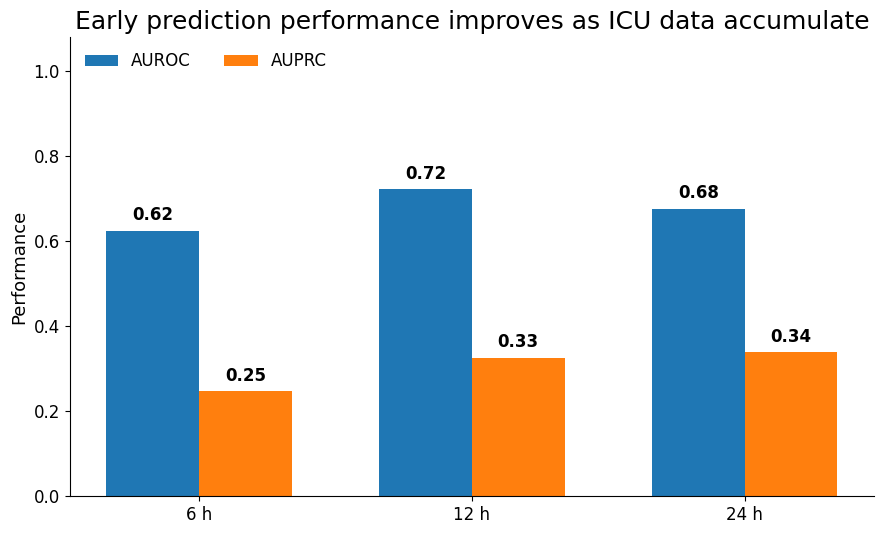

In [ ]:
p = metrics_table.sort_values("checkpoint_hours")
x = np.arange(len(p)); w = .34
fig, ax = plt.subplots(figsize=(9,5.5))
b1=ax.bar(x-w/2,p["AUROC"],w,label="AUROC")
b2=ax.bar(x+w/2,p["AUPRC"],w,label="AUPRC")
for bars in (b1,b2):
    for b in bars: ax.text(b.get_x()+b.get_width()/2,b.get_height()+.025,f"{b.get_height():.2f}",ha="center",fontweight="bold")
ax.set_xticks(x,[f"{int(h)} h" for h in p.checkpoint_hours]); ax.set_ylim(0,1.08)
ax.set_ylabel("Performance"); ax.set_title("Early prediction performance improves as ICU data accumulate")
ax.spines[["top","right"]].set_visible(False); ax.legend(frameon=False,ncol=2,loc="upper left")
finish("slide_visual_1_performance.png")


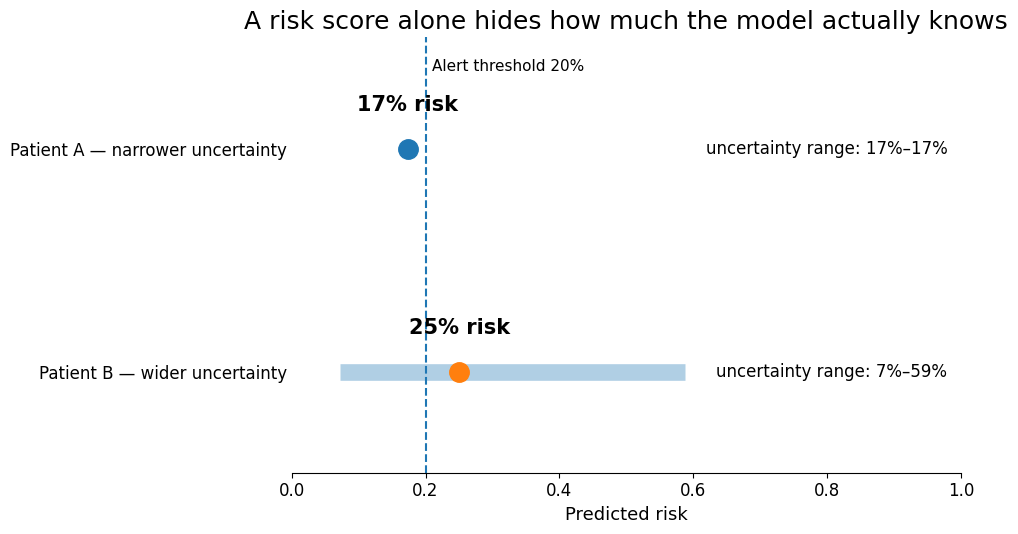

 stay_id  risk_score  missing_data_low  missing_data_high  missing_fraction                                         confidence_flag
38137964    0.173097          0.173097           0.173097          0.083333    OK - missing data does not change the alert decision
37293400    0.250401          0.072542           0.587909          0.027778 LOW - missing-data uncertainty crosses action threshold


In [ ]:
H=24
d=checkpoint_results[H].copy(); d["md_width"]=d.missing_data_high-d.missing_data_low
# Find a pair with risk within 8 percentage points and maximally different uncertainty.
best=None
for i in range(len(d)):
    for j in range(i+1,len(d)):
        gap=abs(d.iloc[i].risk_score-d.iloc[j].risk_score)
        if gap<=.08:
            score=abs(d.iloc[i].md_width-d.iloc[j].md_width)
            if best is None or score>best[0]: best=(score,i,j)
if best is None:
    ids=d.nlargest(2,"risk_score").index
else: ids=[d.index[best[1]],d.index[best[2]]]
pair=d.loc[ids].sort_values("md_width").reset_index(drop=True)
fig,ax=plt.subplots(figsize=(10,5.5))
y=[1,0]
for k,r in pair.iterrows():
    ax.hlines(y[k],r.missing_data_low,r.missing_data_high,lw=12,alpha=.35)
    ax.plot(r.risk_score,y[k],'o',ms=14)
    ax.text(r.risk_score,y[k]+.17,f"{r.risk_score:.0%} risk",ha='center',fontweight='bold',fontsize=15)
    ax.text(.98,y[k],f"uncertainty range: {r.missing_data_low:.0%}–{r.missing_data_high:.0%}",ha='right',va='center',fontsize=12)
ax.axvline(ACTION_THRESHOLD,ls='--',lw=1.5); ax.text(ACTION_THRESHOLD+.01,1.35,f"Alert threshold {ACTION_THRESHOLD:.0%}",fontsize=11)
ax.set_yticks(y,["Patient A — narrower uncertainty","Patient B — wider uncertainty"]); ax.set_xlim(0,1); ax.set_ylim(-.45,1.5)
ax.set_xlabel("Predicted risk"); ax.set_title("A risk score alone hides how much the model actually knows")
ax.spines[["top","right","left"]].set_visible(False); ax.tick_params(axis='y',length=0)
finish("slide_visual_2_same_risk_different_certainty.png")
print(pair[["stay_id","risk_score","missing_data_low","missing_data_high","missing_fraction","confidence_flag"]].to_string(index=False))


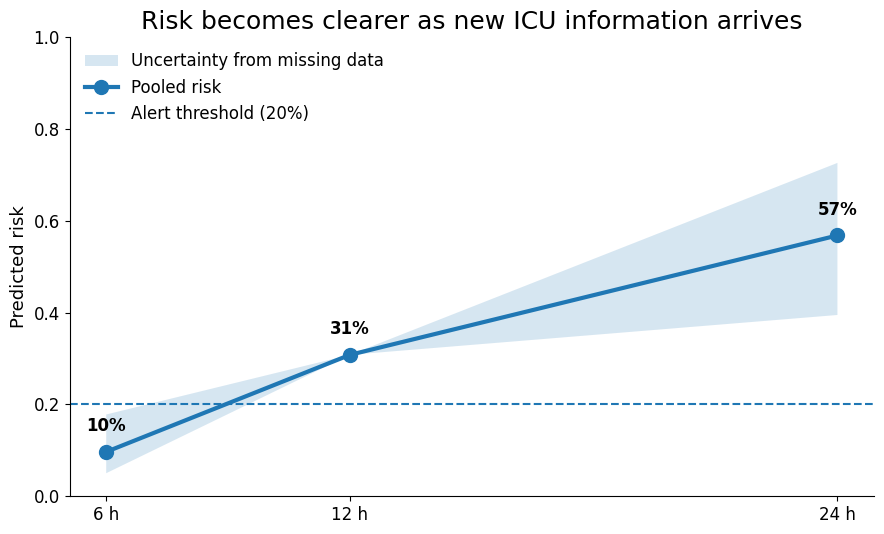

Selected subject: 10004235


In [ ]:
wide=all_results.pivot_table(index="subject_id",columns="checkpoint_hours",values="risk_score")
complete=wide.dropna(subset=CHECKPOINTS)
if len(complete):
    sid=(complete[24]-complete[6]).abs().idxmax()
else:
    sid=all_results.groupby("subject_id").checkpoint_hours.nunique().idxmax()
p=all_results[all_results.subject_id==sid].sort_values("checkpoint_hours")
fig,ax=plt.subplots(figsize=(9,5.5))
ax.fill_between(p.checkpoint_hours,p.missing_data_low,p.missing_data_high,alpha=.18,label="Uncertainty from missing data")
ax.plot(p.checkpoint_hours,p.risk_score,marker='o',lw=3,ms=10,label="Pooled risk")
for _,r in p.iterrows(): ax.text(r.checkpoint_hours,r.risk_score+.045,f"{r.risk_score:.0%}",ha='center',fontweight='bold')
ax.axhline(ACTION_THRESHOLD,ls='--',lw=1.5,label=f"Alert threshold ({ACTION_THRESHOLD:.0%})")
ax.set_xticks(CHECKPOINTS,["6 h","12 h","24 h"]); ax.set_ylim(0,1); ax.set_ylabel("Predicted risk")
ax.set_title("Risk becomes clearer as new ICU information arrives")
ax.spines[["top","right"]].set_visible(False); ax.legend(frameon=False,loc="upper left")
finish("slide_visual_3_patient_journey.png")
print(f"Selected subject: {sid}")


In [ ]:
import os
import zipfile
from google.colab import files

needed = [
    "features_6h.csv",
    "features_12h.csv",
    "features_24h.csv",
    "risk_scores_with_uncertainty_ALL_CHECKPOINTS.csv",
    "slide_visual_1_performance.png",
    "slide_visual_2_same_risk_different_certainty.png",
    "slide_visual_3_patient_journey.png"
]

with zipfile.ZipFile("ICU_outputs.zip", "w") as z:
    for f in needed:
        if os.path.exists(f):
            z.write(f)
            print("Added:", f)
        else:
            print("MISSING:", f)

files.download("ICU_outputs.zip")

Added: features_6h.csv
Added: features_12h.csv
Added: features_24h.csv
Added: risk_scores_with_uncertainty_ALL_CHECKPOINTS.csv
Added: slide_visual_1_performance.png
Added: slide_visual_2_same_risk_different_certainty.png
Added: slide_visual_3_patient_journey.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>